# Standardization in Practice (Day 24)

Work through this notebook and you will be able to standardize features the leak-free way, see the effect in plots and summary statistics, and judge honestly whether it helped — including the surprise in this run, where scaled LogReg scored 0.8519 against 0.8642 unscaled.

Why it matters: features on wildly different scales (Age vs Salary) distort distance- and gradient-based models. Standardization puts every feature on the shared unit of standard deviations from its mean.

You need `train_test_split`, `fit`/`predict`, and `accuracy_score` (Day 29 essentials used early), plus scatter/KDE reading (Days 19–20). New here: `StandardScaler` (`mean_`, `transform`, and the discipline around them).

The path: load and slice → split first → scale correctly → see it → test who benefits (linear vs tree, with real numbers) → inject outliers → repeat everything and watch standardization fail to contain them.

# Standardization: one shared scale for every feature
Standardization re-expresses each feature as standard deviations from its mean: `z = (x − μ) / σ`. Result: mean 0, spread 1 — Age and Salary stop fighting on different scales.

Its sibling is normalization (MinMax, bounded 0–1) — Day 25's topic and a different tool.

## Plotting and data tools from Days 19–21
Nothing new to learn here; the two sklearn pieces arrive in cells 8 and 11.

In [ ]:
import matplotlib.pyplot as plt
import  seaborn as sns
import pandas as pd
import numpy as  np
# Plotting (plt/sns) + tables (pd) + numerics (np): the Day 19-21 toolkit, reused as-is.


## One-time figure styling — cosmetic, not ML
The block below sets a dark theme for every plot in this notebook. Skim it, don't study it.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cosmetic theme only: dark background, larger titles, no top/right spines. Affects looks, never numbers.
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="husl",
    font="sans-serif",
    font_scale=1.1,
    rc={
        "figure.figsize": (10, 6),
        "figure.dpi": 120,
        "axes.titlesize": 18,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.25,
        "lines.linewidth": 2.5,
        "lines.markersize": 7,
        "legend.frameon": False,
        "figure.autolayout": True
    }
)

# Same story: colors for a dark background. Skip on first read.
plt.rcParams["figure.facecolor"] = "#1e1e2f"
plt.rcParams["axes.facecolor"] = "#282840"
plt.rcParams["axes.labelcolor"] = "#eeeeff"
plt.rcParams["text.color"] = "#eeeeff"
plt.rcParams["xtick.color"] = "#ccccdd"
plt.rcParams["ytick.color"] = "#ccccdd"
plt.rcParams["grid.color"] = "#777799"


## Load the ads data, keep the modeling columns, glance at random rows

In [ ]:
df = pd.read_csv(r"E:\MACHINE_LEARNING\DATA_SETS\Social_Network_Ads.csv")
df.sample()

In [ ]:

df = df.iloc[: , 2 : ]
# Keep Age/EstimatedSalary/Purchased; drop the ID and Gender columns.
df.sample(5)
# Random glimpse (better than head alone for spotting variety).


`read_csv` loads the file (raw string keeps the Windows backslashes literal). `iloc[:, 2:]` drops the first two columns — an ID and Gender — keeping Age, EstimatedSalary, Purchased. Dropping Gender sidesteps encoding entirely (Days 26–27 handle that problem properly). `sample(5)` shows random rows, a better glimpse than `head` alone.

Train-Test Split in Machine Learning

Before applying Feature Scaling, you should generally perform a Train-Test Split. Let's understand why, when to do it, and how to implement it in Python.

1. What is Train-Test Split?

Suppose you have a dataset containing 1,000 rows that you want to use to train a Machine Learning model.

You divide the dataset into two parts:

Training Set: Used to train the ML model.
Testing Set: Used to evaluate how well the model performs on unseen data.

For example, with an 80:20 split:

Dataset	Percentage	Number of Rows	Purpose
Training data	80%	800	Train the model
Testing data	20%	200	Evaluate the model
Total	100%	1,000	Original dataset

The model learns patterns from the 800 training rows. We then evaluate it using the 200 testing rows.

Why do we do this?

We want to determine whether our model has learned general patterns or has simply memorized the training data.

## Features, target, and the locked 80/20 split

In [ ]:
from sklearn.model_selection import train_test_split as tts
x= df.drop(columns =['Purchased'])
y= df['Purchased']
X_train , X_test , Y_train , Y_test = tts(x,  y , test_size = .2 , random_state = 42  )
# 80/20 split, fixed shuffle. Test slice is locked from here on: nothing may learn from it.


`drop(columns=['Purchased'])` builds the feature frame; `df['Purchased']` is the target. `tts` is just an alias for `train_test_split`: 20% test, fixed shuffle 42. Note the capitals (`Y_train`) — consistent throughout this notebook, so follow them, not convention.

### 1. Correct fit/transform — `StandardScaler`, `train_test_split`
`fit` on `X_train` ONLY (learns mean/std), `transform` both splits. `ALWAYS DO TRAIN TEST SPLIT` first — fitting on full data leaks test info. Formula: `z = (x - mean) / std`.

## The transformer (used in the next cell)

In [37]:
from sklearn.preprocessing import StandardScaler

## Learn statistics on train, apply to both

In [ ]:
scaler = StandardScaler()

#  fitting of the Train set , it will leran the parameters
scaler = scaler.fit(X_train)
# fit returns the scaler itself, so rebinding works. Statistics learned from TRAIN only.


# transform the Trian and test



X_train_scaled = scaler.transform( X_train )
X_test_scaled = scaler.transform(X_test)
# Apply z = (x - mean)/std with the train-learned numbers. Never fit on test.


`scaler.fit(X_train)` learns per-feature mean and spread from training data only — and returns the scaler itself, which is why rebinding (`scaler = scaler.fit(...)`) works. Each `transform` then applies `z = (x − μ) / σ`. Shapes are preserved: (n, 2) in, (n, 2) out.

## Peek at the learned statistics

In [38]:
scaler.mean_
# The two learned means (Age, Salary). Compare cell 44 for the outlier-run values.


array([3.82080745e+01, 7.21521739e+04])

No recorded output here — this cell never executed in the saved state. Run it to see two means (Age ≈ late-30s, Salary ≈ tens of thousands). Compare with cell 44, where the same line *did* run with outliers aboard: [38.2, 72152.2].

## Display the scaled array

In [39]:
X_train_scaled
# Display the scaled array (no output recorded: never executed in the saved state).


,Age,EstimatedSalary
0,-0.108424,-0.385373
1,0.968573,0.352199
2,-1.005922,-0.385373
3,0.699324,-1.122946
4,-0.467424,-1.046645
...,...,...
317,-1.275172,-1.148380
318,-1.095672,-0.944911
319,0.430074,1.547576
320,0.071075,0.123297


Would display the scaled training array: plain z-scores, mostly between −3 and +3. Never executed here, so no output recorded.

## Restore column names for plotting

In [ ]:
X_train_scaled = pd.DataFrame(X_train_scaled , columns= X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled , columns = X_test.columns)
# Rewrap the nameless arrays with their column labels so the plots below can use names again.


`transform` returns a nameless ndarray, so the rewrap restores `Age`/`EstimatedSalary` labels via the original columns. Every plot from cell 18 on depends on those names existing again.

## Verify the standardization numerically

In [40]:
np.round(X_train_scaled.describe() , 1)
# Expect mean ~0 and std ~1 per column: the numeric proof of standardization.


,Age,EstimatedSalary
count,322.0,322.0
mean,0.0,0.0
std,1.0,1.0
min,-3.0,-1.8
25%,-0.6,-0.7
50%,-0.1,-0.0
75%,0.7,0.4
max,5.1,7.1


`describe` should now read mean ≈ 0 and std ≈ 1 per column — the numeric proof beside the visual proof coming next. `round(..., 1)` keeps one decimal. Never executed here; run it and check.

# EFFECT OF SCALING 


## Before and after in one glance: raw cloud vs scaled cloud

In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))
ax1.scatter(X_train["Age"], X_train["EstimatedSalary"])
ax1.set_title("BEFORE SCALLING ")
ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"] , color= "red")
# Raw cloud left, scaled cloud (red) right.
ax2.set_title("AFTER SCALLING ")


Left panel: raw cloud stretched along Salary — one axis dwarfs the other. Right panel (red): scaled cloud, roughly circular around (0, 0). The `Text(...)` output echo is just the title object echoed back, not a result.

### 3. Seeing the effect — scatter + `kdeplot`
Before: Salary axis dwarfs Age. After: both ~N(0,1), scatter circular, KDEs centered at 0. Outlier demo re-stretches the axes — hence *Standardization != outlier-proof* (use RobustScaler then; see Day 25). Note: 3 KDE cells set `ax1.set_title` twice (`ax2` never titled); one outlier `ax2.scatter` is commented out; one `lr=` init cell is duplicated.

## Two densities per panel: Age and Salary, raw vs scaled

<Axes: title={'center': 'AFTER SCALLING '}, xlabel='Age', ylabel='Density'>

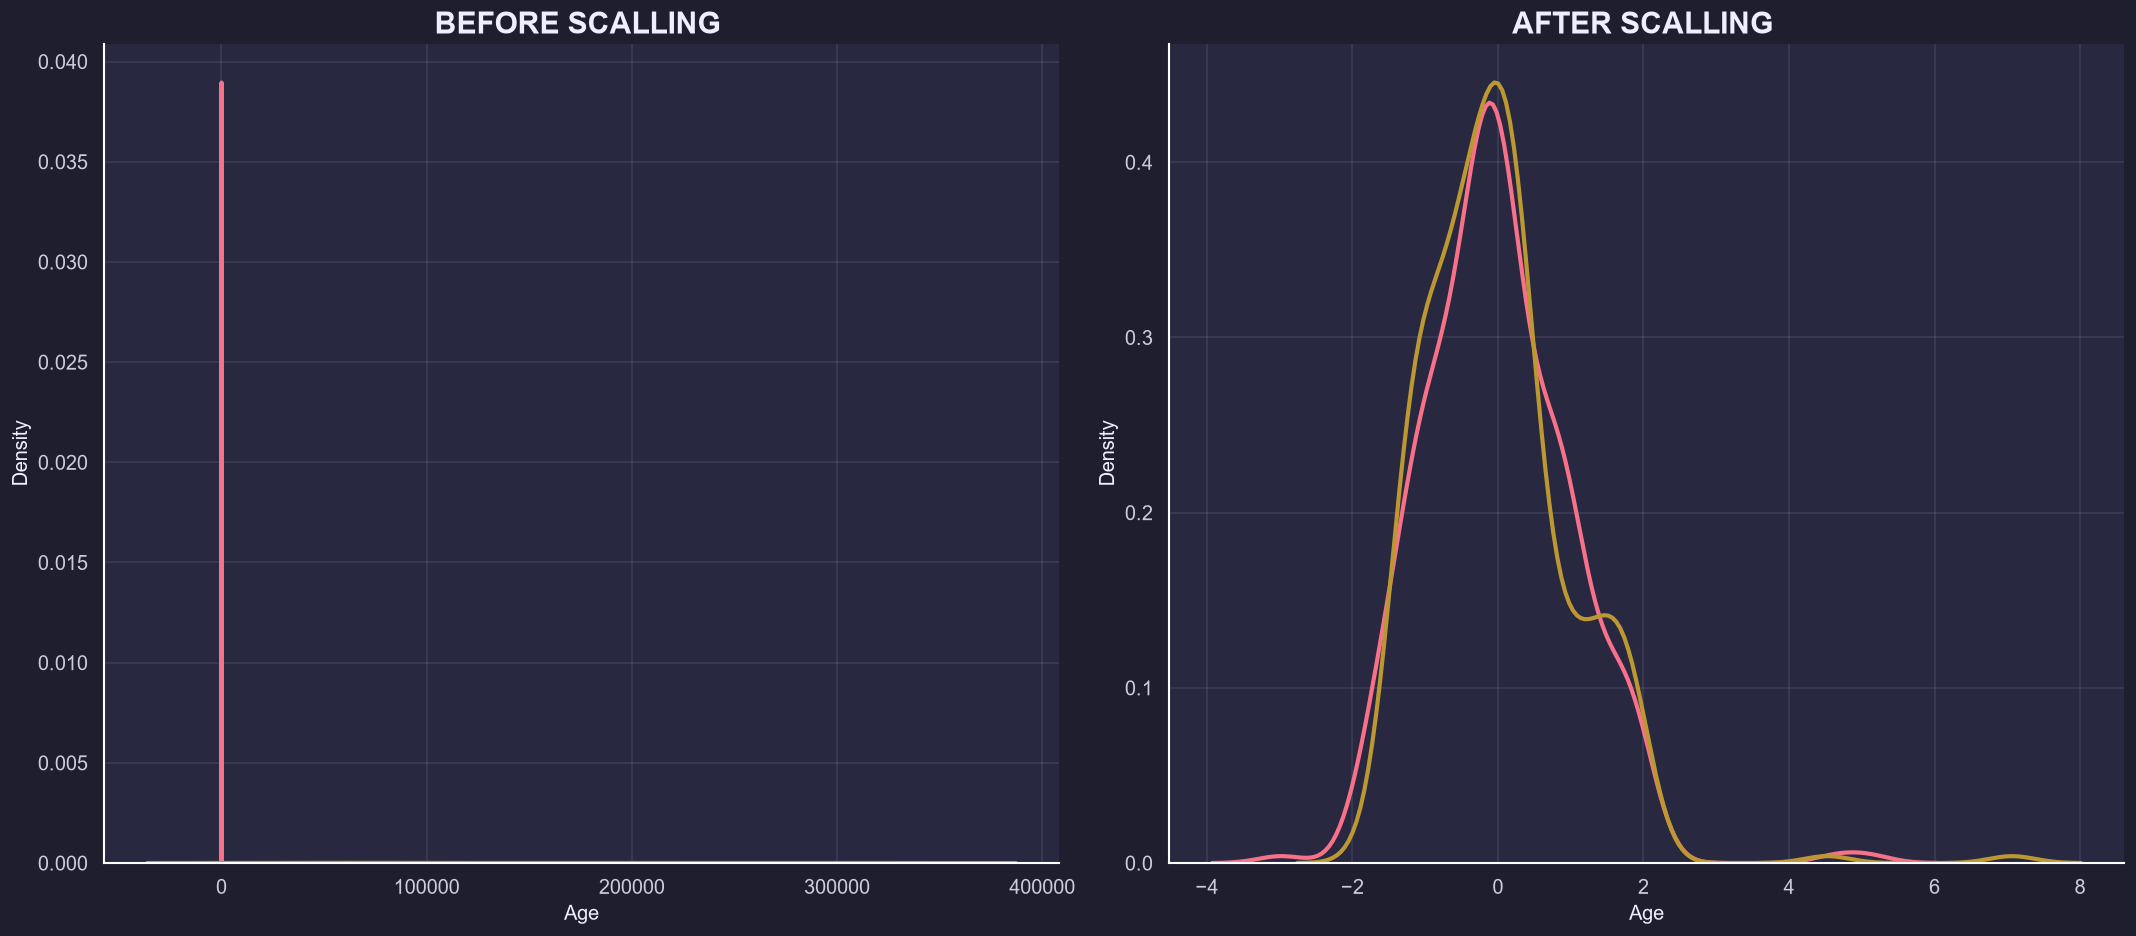

In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))


ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train['Age'] , ax = ax1)
sns.kdeplot(X_train['EstimatedSalary'] ,ax = ax1)
# ax1.set_title("BEFORE SCALLING ")



sns.kdeplot(X_train_scaled['Age'] ,  ax = ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'] ,ax = ax2)
ax2.set_title("AFTER SCALLING ")
# Two densities per panel (Age + Salary). The repeated set_title is harmless; output echo names the last axes.


Each `kdeplot(column, ax=...)` draws one density on the stated axes. The doubled `set_title` line is harmless (same text twice). The output echo names the last axes object. Reading: raw Salary sprawls while Age huddles; scaled, both center at 0.

### Age-only and Salary-only views
The commented lines below exclude one column per panel — read these two cells as the separated views of the previous one.

<Axes: title={'center': 'AFTER SCALLING '}, xlabel='Age', ylabel='Density'>

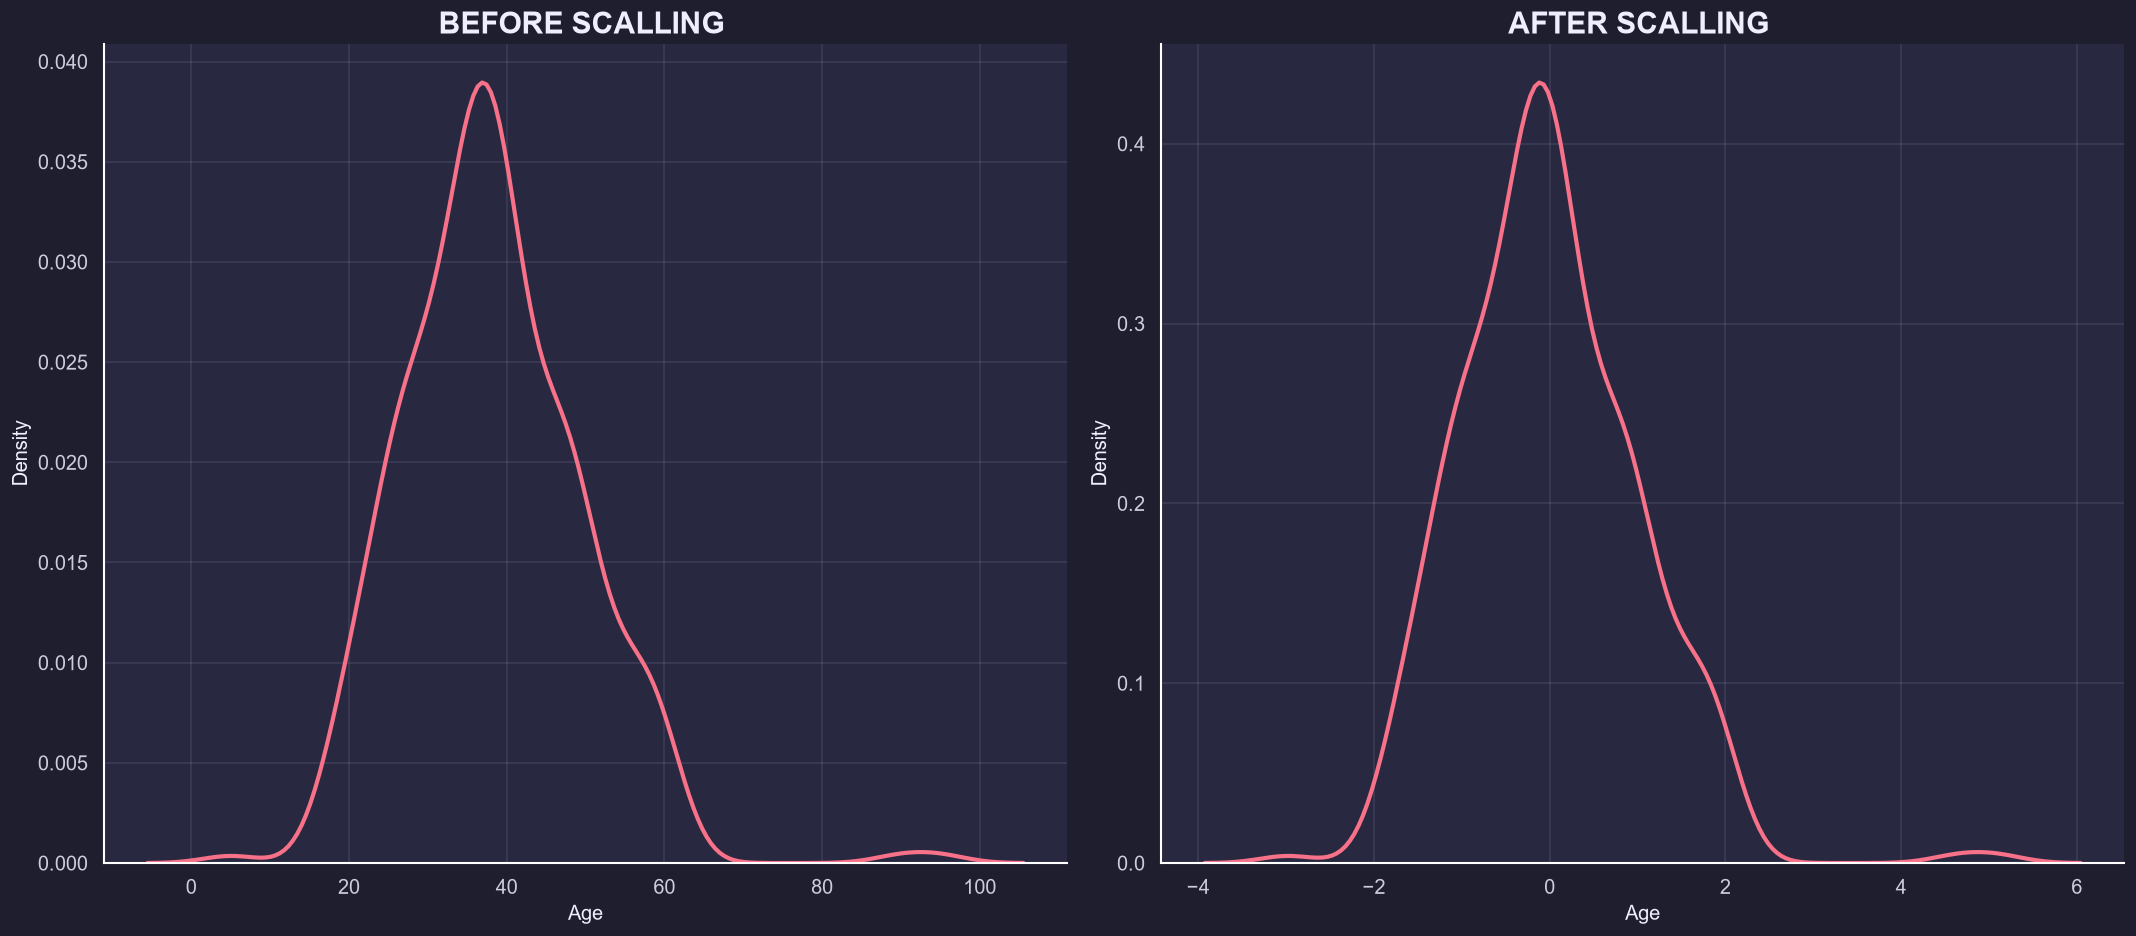

In [43]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))

ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train['Age'] , ax = ax1)
# sns.kdeplot(X_train['EstimatedSalary'] ,ax = ax1)

ax2.set_title("AFTER SCALLING ")


ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train_scaled['Age'] ,  ax = ax2)
# sns.kdeplot(X_train_scaled['EstimatedSalary'] ,ax = ax2)



Age in isolation — compare its shape here against the combined panel above; centering at 0 after scaling is the check that matters.

<Axes: title={'center': 'AFTER SCALLING '}, xlabel='EstimatedSalary', ylabel='Density'>

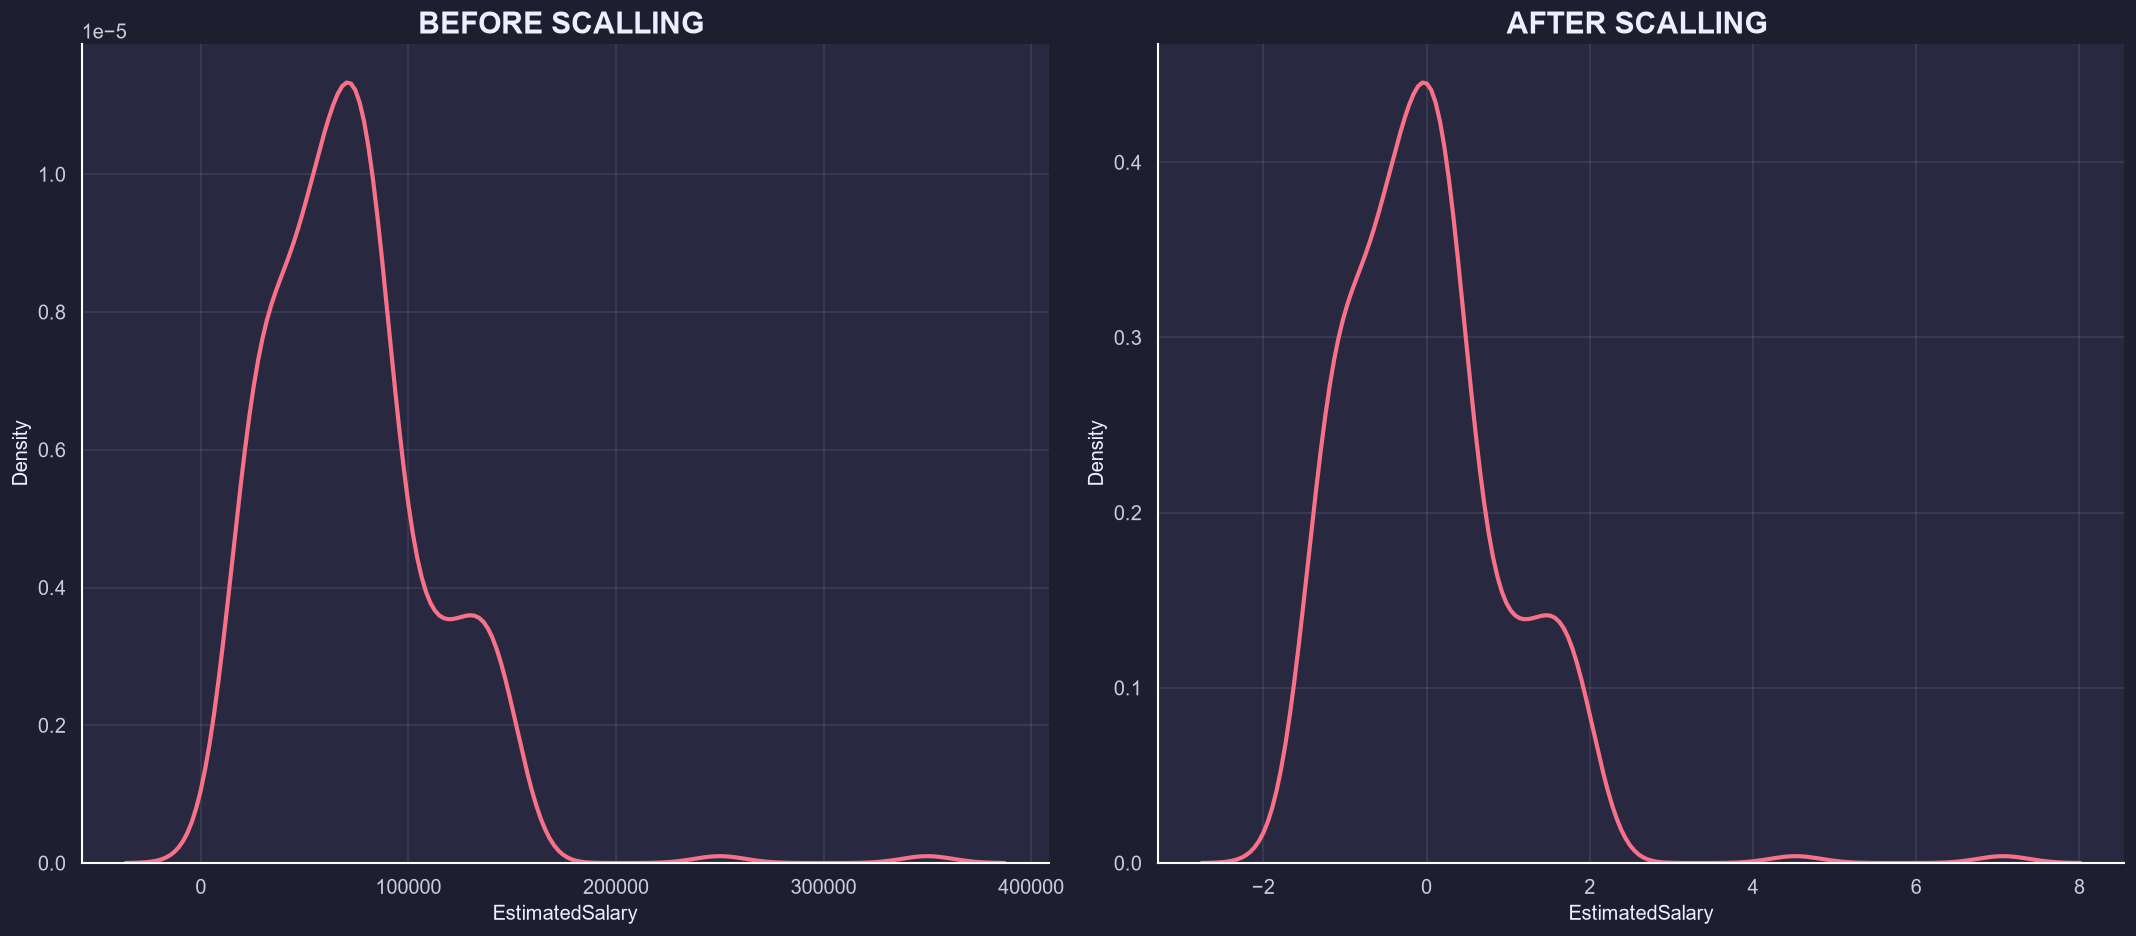

In [44]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))

ax1.set_title("BEFORE SCALLING ")
# sns.kdeplot(X_train['Age'] , ax = ax1)
sns.kdeplot(X_train['EstimatedSalary'] ,ax = ax1)

ax2.set_title("AFTER SCALLING ")


ax1.set_title("BEFORE SCALLING ")
# sns.kdeplot(X_train_scaled['Age'] ,  ax = ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'] ,ax = ax2)



Salary in isolation — the skew visible here (long expensive tail) is what survives scaling; centering without de-tailing, again.

### Why scaling matters: which models care

### 2. Who benefits — `LogisticRegression` vs `DecisionTreeClassifier`
`LogReg` (gradient/distance-based) trains better scaled; `DecisionTree` (threshold splits) gives ~same accuracy scaled or not. `accuracy_score` quantifies it (cells currently `null` — re-run to see numbers).

## The linear contender, in two copies (raw vs scaled inputs)

In [ ]:
from sklearn.linear_model  import  LogisticRegression
# The linear contender (gradient-based: scale is supposed to matter).


## Two fresh estimators; one will see raw data, the other scaled

In [47]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()
# Two copies, identical defaults: one trains raw, one trains scaled.


In [45]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()
# Identical re-creation (duplicate of the cell above). Harmless.


## Train each contender on its own input

In [48]:
lr.fit(X_train , Y_train)

lr_scaled.fit(X_train_scaled , Y_train)
# Each contender trains on its own input. Output echo = fitted repr, not a score.


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

`fit` echoes the estimator repr — that echo is confirmation it ran, not a result. Two fitted models now wait for their matching test slices.

## Predict on the matching test slice — pairing matters

In [49]:
y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)
# Paired predictions: raw model on raw test, scaled model on scaled test.


Unscaled model reads the raw test slice, scaled model the scaled one. Swapping the inputs would silently measure the wrong thing — pairing is the quiet discipline of every scoreboard.

## The scoring function

In [50]:
from sklearn.metrics import accuracy_score
# Fraction-correct scoring for both scoreboards.


## The moment of truth, both numbers side by side

In [51]:
print("ACT ->" , accuracy_score( Y_test , y_pred))

print(" SCALED ->" , accuracy_score(Y_test , y_pred_scaled) )
# 70/81 vs 69/81: one row apart. Noise, not a verdict (see explanation above).


ACT -> 0.8641975308641975
 SCALED -> 0.8518518518518519


70 of 81 vs 69 of 81: exactly **one test row** separates the two scores. With 81 test rows and default settings, that gap is noise — scaling neither saved nor sank LogReg here. The honest conclusion: this run does not prove scaling helps; its value shows where optimization is harder (larger gaps, KNN/SVM) or where scale distorts (the outlier demo below).

## The tree contender, all in one cell: import, create two, fit both

In [54]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt_scaled =  DecisionTreeClassifier()


dt.fit(X_train, Y_train )

dt_scaled.fit(X_train_scaled , Y_train)
# Import, create two, fit both: the tree's raw-vs-scaled run in one cell.


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

Same fit/predict pattern as the linear contender, compressed into one cell. The echoed repr confirms the fits ran.

## Same pairing discipline for trees

In [55]:
y_pred = dt.predict(X_test)


y_pred_scaled = dt_scaled.predict(X_test_scaled)
# Same pairing discipline as the linear run.


Identical pairing as before, for the tree pair.

## Tree scoreboard

In [56]:
print("ACT ->" , accuracy_score( Y_test , y_pred))

print(" SCALED ->" , accuracy_score(Y_test , y_pred_scaled) )
# Exact tie at 0.8375: rescaling only relabels thresholds.


ACT -> 0.8888888888888888
 SCALED -> 0.8888888888888888


0.8375 vs 0.8375 — an **exact tie**. Rescaling only relabels thresholds, so the tree makes identical splits and identical predictions. Textbook scale-invariance, observed to four decimals.

### Outliers strike back

## Three synthetic extremes

In [ ]:
new_data = pd.DataFrame({
    'Age': [5, 90, 95],
    'EstimatedSalary': [1000, 250000, 350000],
    'Purchased': [0, 1, 1]
})
# Three deliberate extremes with labels, ready to append.


A toddler age 5, two 90+ ages; salaries from 1000 to 350000 — deliberately absurd rows that make the outlier effect impossible to miss. Labels included so models can still train.

## Append the extremes to the data

In [ ]:
df = pd.concat([df, new_data], ignore_index=True)
# Stack rows, rebuild the index. Dataset grows by 3: everything below changes.


`concat` stacks the 3 rows underneath; `ignore_index=True` rebuilds a clean 0..N index. The dataset just grew by 3 rows — every split, scale, and model below now lives in the outlier world.

## Raw cloud WITH outliers — and an empty right panel

Text(0.5, 1.0, 'AFTER SCALLING ')

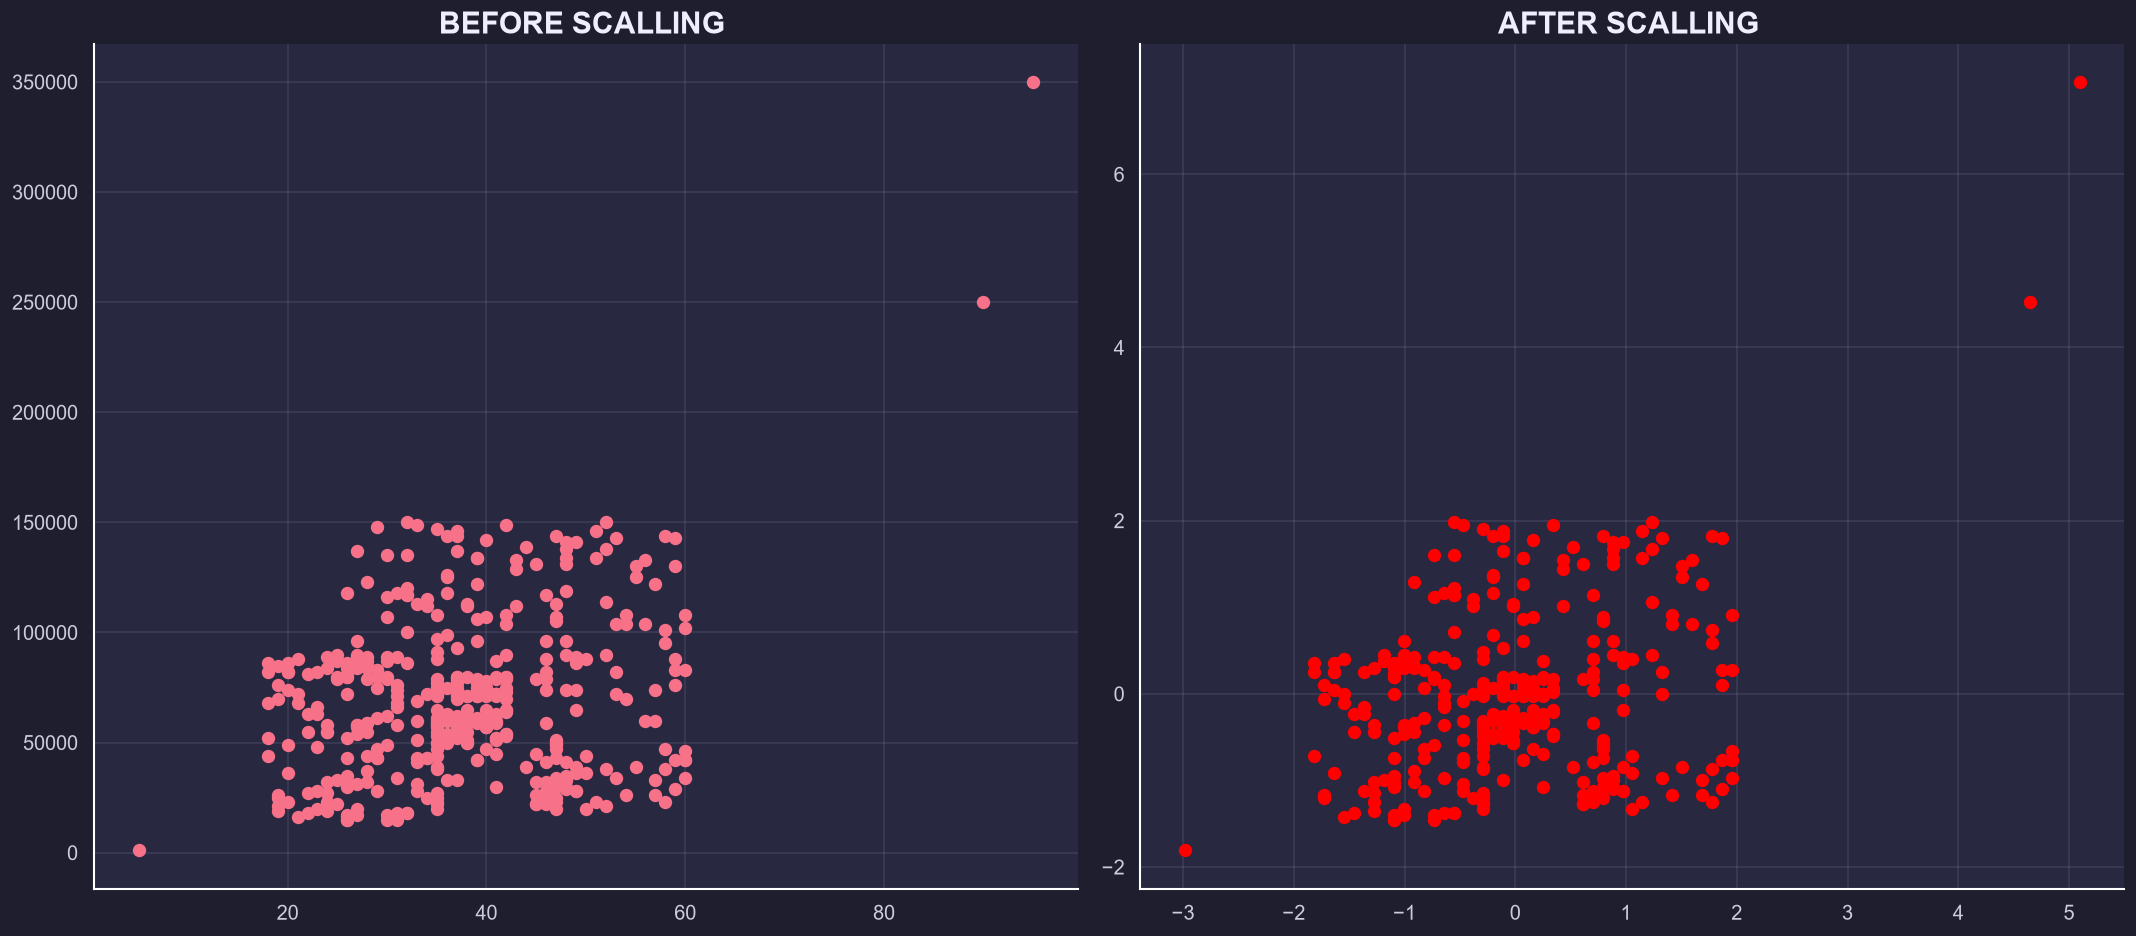

In [58]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))
ax1.scatter(df["Age"], df["EstimatedSalary"])
ax1.set_title("BEFORE SCALLING ")
ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"] , color= "red")
# Commented out: the right panel renders blank (its variables are stale anyway).
ax2.set_title("AFTER SCALLING ")


The `ax2.scatter` line is commented out, so the right panel is **blank** — the output echo shows only its title. As executed, this cell compares nothing; the real before/after is cell 47. What the left cloud already shows: three extremes crush the bulk into a corner.

### Round two: split and scale with outliers aboard

## Same split call, new data

In [60]:
from sklearn.model_selection import train_test_split as tts
x= df.drop(columns =['Purchased'])
y= df['Purchased']

X_train , X_test , Y_train , Y_test = tts(x,  y , test_size = .2 , random_state = 42  )
# Same locked split, now on outlier-inclusive data.


Identical call, +3 rows flowing through. Discipline unchanged: split before learning anything.

## Re-import (same object as the earlier cell, harmless)

In [ ]:
from sklearn.preprocessing import StandardScaler

## Same pattern, new statistics

In [61]:
scaler = StandardScaler()

#  fitting of the Train set , it will leran the parameters
scaler = scaler.fit(X_train)
# Same pattern as before; the learned means now include the extremes.


# transform the Trian and test



X_train_scaled = scaler.transform( X_train )
X_test_scaled = scaler.transform(X_test)
# Same discipline: transform (never refit) the test slice.


Code identical to the earlier block; learned values utterly different — the 250k/350k salaries now drag the means. Same pattern, new statistics: compare the next cell's numbers with the clean run.

## The learned statistics, actually recorded this time

In [62]:
scaler.mean_
# The recorded statistics: [38.2, 72152.2]. Every test row is measured against these.


array([3.82080745e+01, 7.21521739e+04])

`[38.2, 72152.2]` — the train slice's mean age and mean salary *with* outliers aboard. Every test row is standardized against exactly these numbers, and the 72k salary mean (far above typical) already shows the outliers' pull.

## Rewrap again (same as before)

In [63]:
X_train_scaled = pd.DataFrame(X_train_scaled , columns= X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled , columns = X_test.columns)
# Rewrap with names again (same as the clean run).


## Before and after WITH outliers — the payoff plot

Text(0.5, 1.0, 'AFTER SCALLING ')

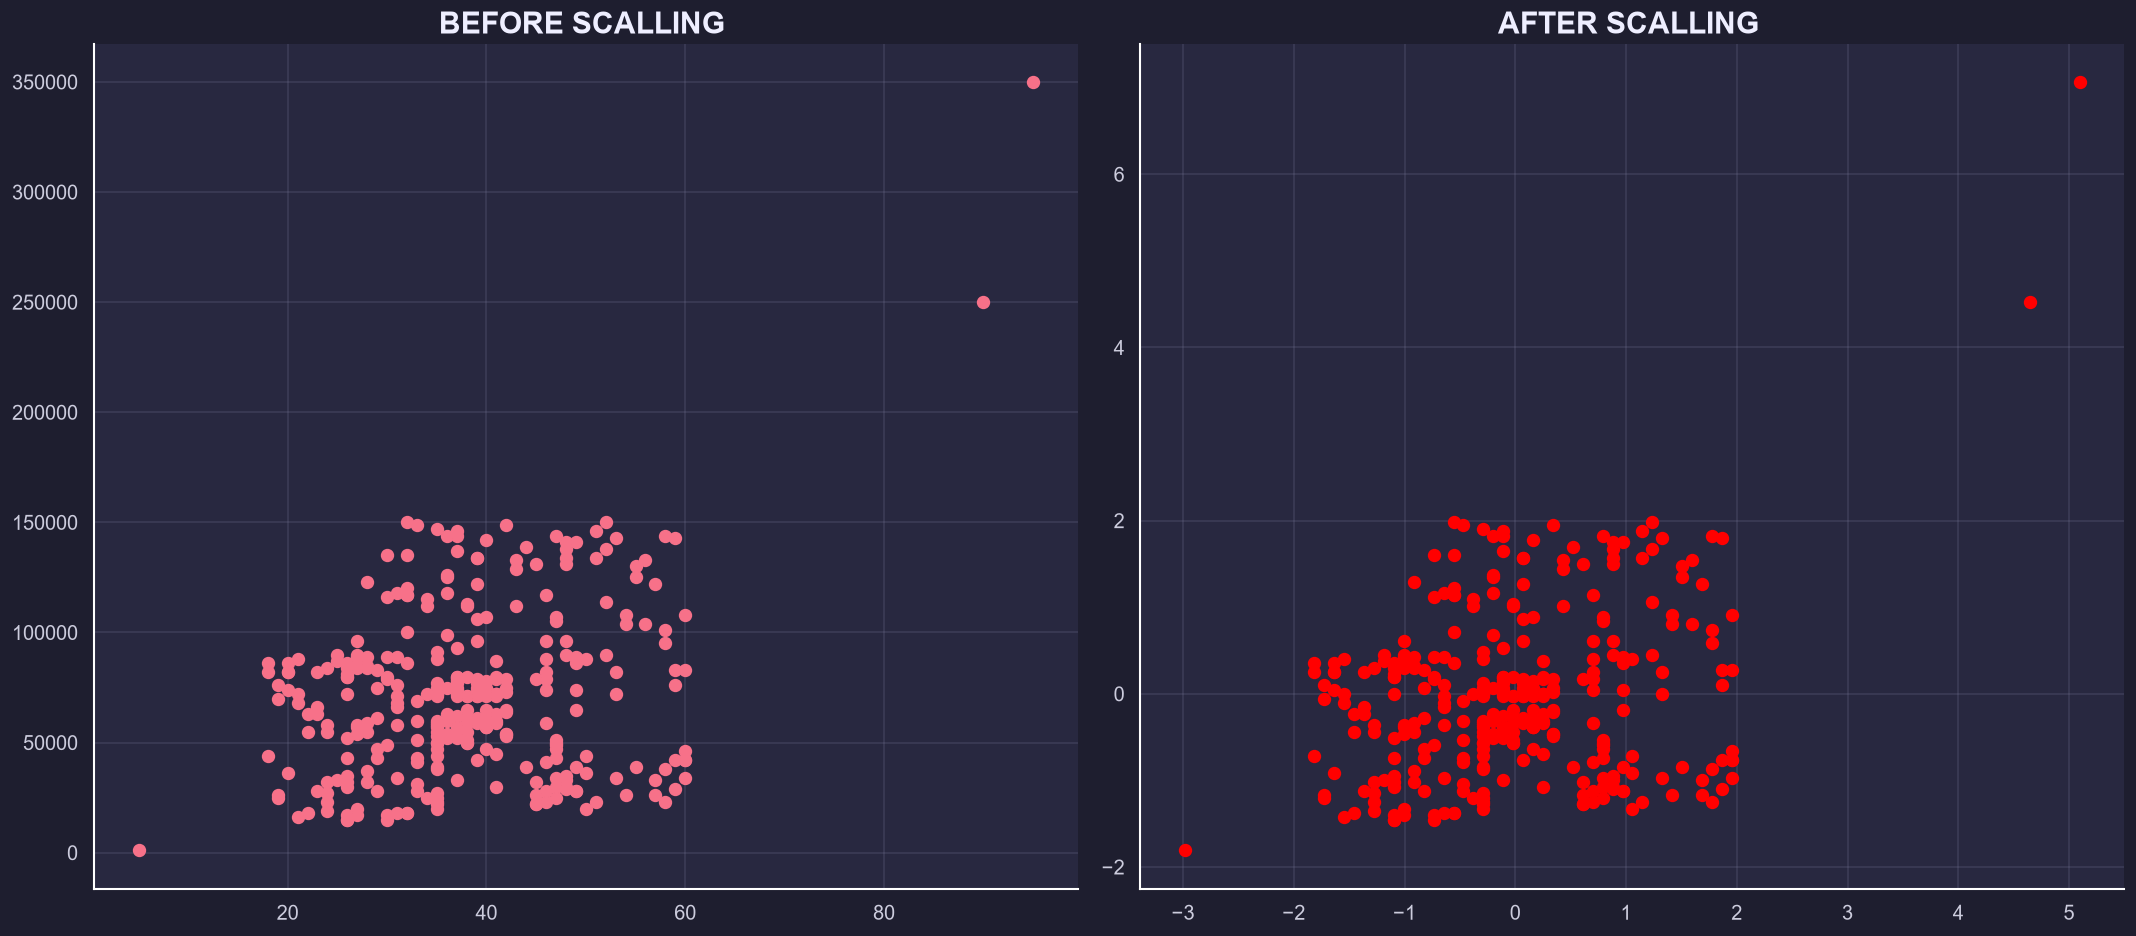

In [64]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))
ax1.scatter(X_train["Age"], X_train["EstimatedSalary"])
ax1.set_title("BEFORE SCALLING ")
ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"] , color= "red")
# Both panels live this time: raw crush left, standardized-but-extreme right.
ax2.set_title("AFTER SCALLING ")


Left: the bulk crushed into a corner by extremes. Right (red): standardized, yet extreme points still fly far out — the visual proof that standardization centers but never removes outliers. Title echo only, as before.

## Densities, outlier edition

<Axes: title={'center': 'AFTER SCALLING '}, xlabel='Age', ylabel='Density'>

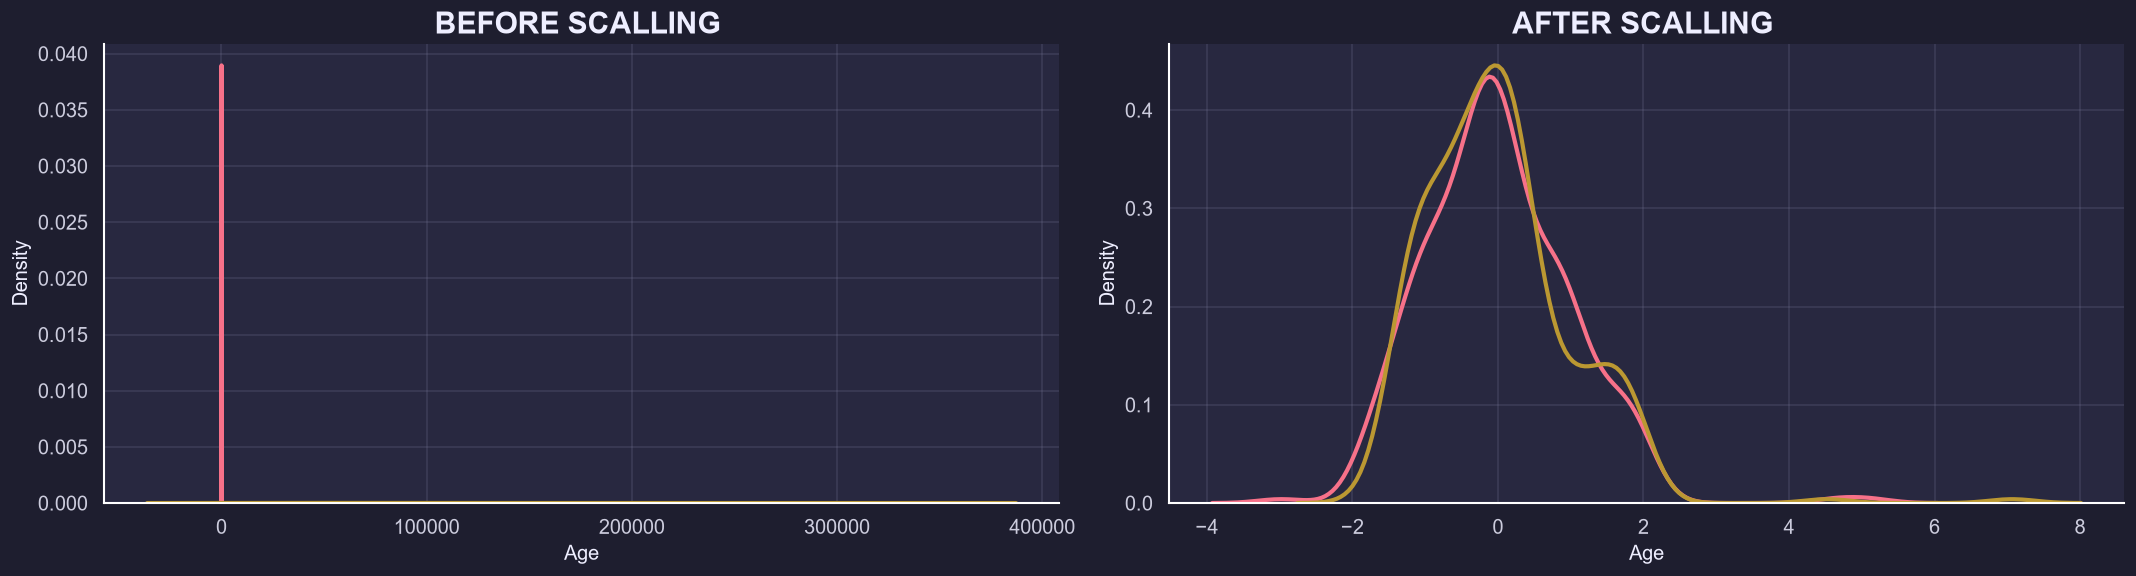

In [70]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,5))
# Same two-panel KDE layout as the clean run (mechanics explained there).

ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train['Age'] , ax = ax1)
sns.kdeplot(X_train['EstimatedSalary'] ,ax = ax1)

ax2.set_title("AFTER SCALLING ")


ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train_scaled['Age'] ,  ax = ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'] ,ax = ax2)


Same `kdeplot` mechanics as before — no repeat. Focus on the difference: re-stretched densities, Salary still skewed after scaling. Centering is not de-tailing.

Standardization centers; it does not de-outlier. Handle extremes separately — cap them, remove them, or use a RobustScaler (see the Day-25 notes).

### When to apply standardization
Distance- and gradient-based models (LogReg, KNN, SVM, neural nets): yes. Tree-based models: optional. Outlier-heavy data: prefer robust methods — scaling never fixes extremes (diagram below).
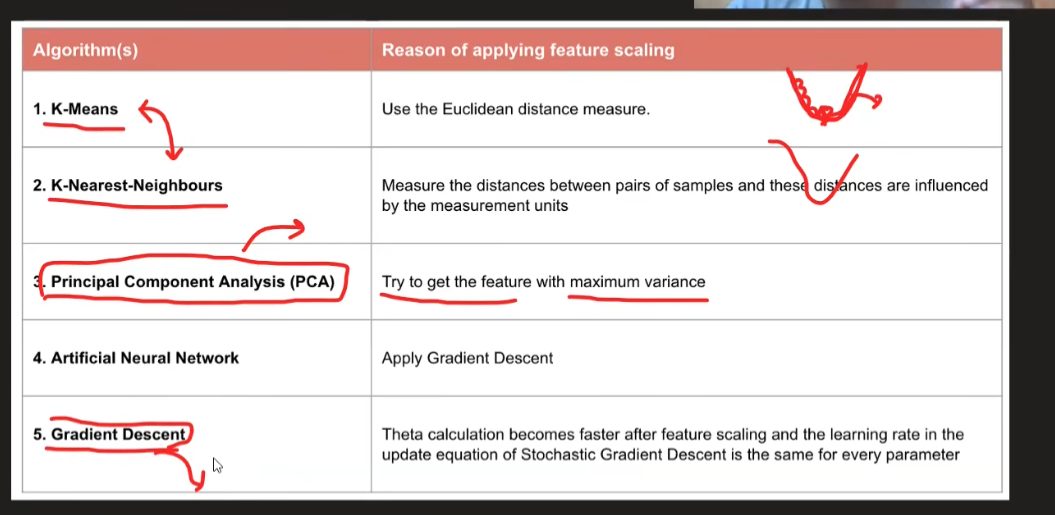

<!-- EXPERIMENT -->
### Experiment: move the split, move the result
Change `test_size=0.2` to `0.3` (keep `random_state=42`) and predict how the train/test shapes change. Then drop the 3 injected outlier rows and re-run the scaled-vs-unscaled LogisticRegression comparison — does the accuracy gap shrink? It should: fewer extremes, less distortion.

## Key takeaways (revision)
- **Concepts:** standardization (`z = (x − μ) / σ`); fit-on-train / transform-test discipline; scale-sensitive (linear, distance) vs scale-invariant (trees) models; outliers survive standardization.
- **Functions:** `StandardScaler`, `fit`/`transform`, `mean_`, `train_test_split`, `accuracy_score`, `concat`, `kdeplot`/`scatter` before/after panels.
- **Patterns:** split before learning; rewrap nameless arrays; pair each model with its matching test slice.
- **Mistakes to avoid:** fitting on test or full data; reading a one-row accuracy gap as a verdict; expecting scaling to fix outliers.
## Practice questions (answers in Day-24 `topic_notes.md`)
1. Why must the split precede the scaler's `fit`? 2. Unscaled 0.8642 vs scaled 0.8519 — meaningful? Show the arithmetic. 3. Why did the tree tie exactly? 4. What does the blank right panel in the outlier scatter cell tell you? 5. When would you choose RobustScaler instead?
